# 전진Unit 캐리어 스톱퍼CY — 전진감지 ON 길이와 전진→후진 전환 (2026-09-10 ~ 10-15, 평일)

질문
1. 전진감지가 켜져 있는 길이가 거의 같은가? 길어지면 에러로 잡을 수 있나?
2. 후진감지는 전진감지가 꺼지자마자(또는 살짝 뒤) 들어오나? 사이클마다 얼마 차이인가?

한 사이클: SOL ON → 전진감지 ON (약 2.6~3.1초) → SOL OFF → 전진감지 OFF → 후진감지 ON (약 9.5초) → 후진감지 OFF → 다음 전진감지 ON

- DB 기록 간격이 약 0.52초라 개별 시간은 ±0.5초 정밀도다(2.6 / 3.1 / 3.6초로 뭉침). 하루 평균은 위상이 섞여 더 작은 변화도 보인다.
- 제외: 사이클 안에서 컨베이어가 2초 넘게 멈춘 것(`moving`), DB 기록이 0.7초 넘게 빈 것(`ok_on`, `ok_trans`).
- 데이터 받기: `python parkkt/conv/conv_tag_pull.py stopper_fwd`, 카운터는 `conv_wagon_reset_pull.py`

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("../.."))
import importlib, conv_stopper as cs, conv_tag_pull as ct, conv_wagon_reset as cw, conv_wagon_reset_pull as cp
for m in (cs, ct, cw, cp): importlib.reload(m)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 240); pd.set_option("display.max_rows", 60)
plt.rc("font", family="Malgun Gothic" if os.name == "nt" else "AppleGothic"); plt.rc("axes", unicode_minus=False)
OUT = "../analysis_out/conv_stopper_fwd"; os.makedirs(OUT, exist_ok=True)

S = ct.load_days("stopper_fwd"); df = cp.load_days()
r = cs.stopper_cycles(S, df, cw)
r.to_csv(f"{OUT}/cycles.csv", index=False, encoding="utf-8-sig")
print(f"사이클 {len(r)}개 / 정지 없음 {int(r['moving'].sum())} / ON 길이 판단 가능(DB 끊김 없음) {int(r['ok_on'].sum())} / 전환 판단 가능 {int(r['ok_trans'].sum())}")

사이클 103772개 / 정지 없음 103022 / ON 길이 판단 가능(DB 끊김 없음) 102801 / 전환 판단 가능 102957


## 1. 전진감지 ON 길이

In [2]:
ok = r[r["ok_on"]]
print("ON 길이(초) 분포 (0.1초 단위, 100건 이상):"); display(ok["on_s"].round(1).value_counts().sort_index().loc[lambda s: s >= 100].to_frame("사이클").T)
display(ok.groupby(np.where(ok["on"] < pd.Timestamp("2026-09-12"), "09-10~11", "09-14~"))["on_s"]
        .describe(percentiles=[.01, .5, .99, .999]).round(2))
print("SOL(명령) 대비: SOL ON→전진 ON, SOL OFF→전진 OFF (초)")
display(pd.DataFrame({c: ok[c].round(1).value_counts().sort_index() for c in ["sol_on_to_fwd_on_s", "sol_off_to_fwd_off_s"]}).fillna(0).astype(int).T)
print(f"ON 길이와 SOL 길이 상관: {ok['on_s'].corr(ok['sol_s']):.2f}")

ON 길이(초) 분포 (0.1초 단위, 100건 이상):


on_s,2.1,2.5,2.6,2.7,3.1,3.2,3.6,3.7
사이클,115,547,61742,4417,26537,6840,1486,1000


,count,mean,std,min,1%,50%,99%,99.9%,max
09-10~11,8941.0,3.06,0.29,2.5,2.57,3.12,3.69,3.73,3.76
09-14~,93860.0,2.78,0.26,0.5,2.55,2.62,3.63,3.69,6.36


SOL(명령) 대비: SOL ON→전진 ON, SOL OFF→전진 OFF (초)


,0.0,0.2,0.3,0.4,0.5,0.6,0.7,15.1
sol_on_to_fwd_on_s,48914,9,11,63,52584,1213,6,1
sol_off_to_fwd_off_s,66866,0,0,39,35220,673,3,0


ON 길이와 SOL 길이 상관: 0.22


### 날짜별 — 길어지고 있나

,사이클,ON_평균,ON_p99,ON_최대,SOL_평균,SOL에서_전진ON,SOL에서_전진OFF,전진OFF_후진ON_평균,전진OFF_후진ON_최대
date,,,,,,,,,
09-10,4474,3.063,3.688,3.756,3.166,0.285,0.182,0.211,0.647
09-11,4467,3.053,3.684,3.756,3.146,0.278,0.186,0.206,0.664
09-14,4144,2.788,3.630,3.710,2.886,0.280,0.182,0.184,0.644
09-15,4324,2.779,3.628,3.710,2.863,0.270,0.186,0.184,0.688
09-16,4328,2.791,3.646,5.679,2.880,0.274,0.184,0.189,0.604
09-17,4274,2.791,3.631,3.717,2.882,0.276,0.185,0.178,0.601
09-18,4411,2.763,3.621,6.248,2.861,0.275,0.177,0.191,0.616
09-21,4486,2.788,3.622,3.703,2.871,0.266,0.183,0.186,0.643
09-22,4402,2.785,3.649,3.711,2.874,0.275,0.186,0.186,0.610


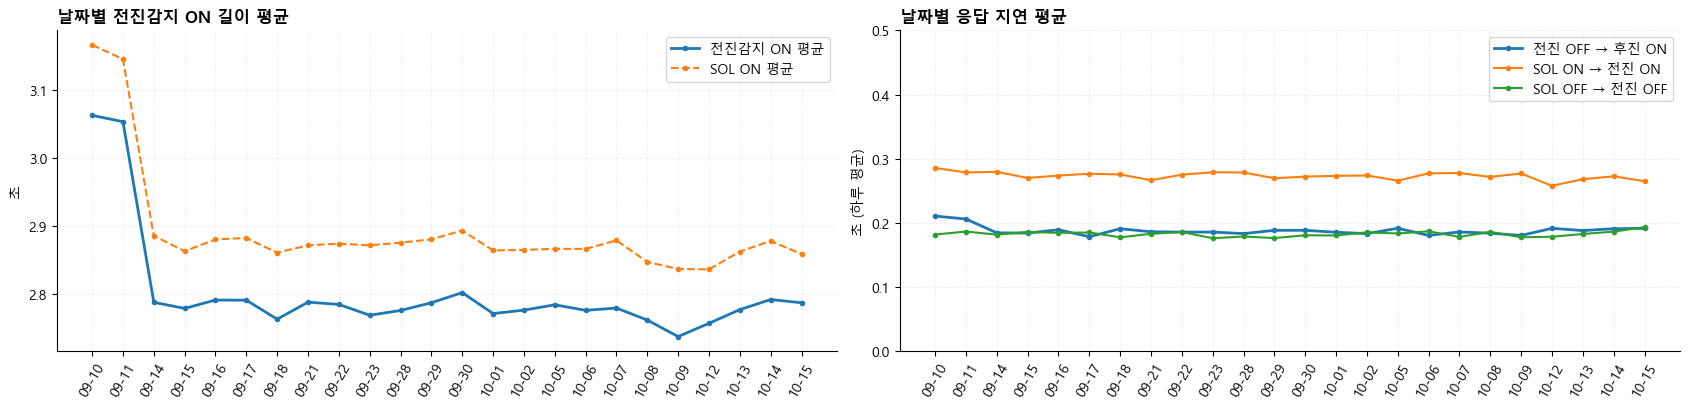

In [3]:
D = cs.daily(r); display(D.round(3)); D.to_csv(f"{OUT}/daily.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(1, 2, figsize=(17, 4.2))
ax[0].plot(D.index, D["ON_평균"], ".-", lw=2, label="전진감지 ON 평균"); ax[0].plot(D.index, D["SOL_평균"], ".--", lw=1.5, label="SOL ON 평균")
ax[0].set_ylabel("초"); ax[0].set_title("날짜별 전진감지 ON 길이 평균", fontweight="bold", loc="left"); ax[0].legend()
ax[1].plot(D.index, D["전진OFF_후진ON_평균"], ".-", lw=2, label="전진 OFF → 후진 ON")
ax[1].plot(D.index, D["SOL에서_전진ON"], ".-", lw=1.5, label="SOL ON → 전진 ON")
ax[1].plot(D.index, D["SOL에서_전진OFF"], ".-", lw=1.5, label="SOL OFF → 전진 OFF")
ax[1].set_ylabel("초 (하루 평균)"); ax[1].set_ylim(0, 0.5); ax[1].set_title("날짜별 응답 지연 평균", fontweight="bold", loc="left"); ax[1].legend()
for a in ax:
    a.tick_params(axis="x", rotation=60); a.grid(alpha=0.3, ls=":"); a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(f"{OUT}/daily.png", dpi=100)

### 길게 나온 사이클 (3.7초 초과) — 센서가 늦은 건가, 명령(SOL)이 길었던 건가

In [4]:
lg = ok[ok["on_s"] > 3.7].sort_values("on_s", ascending=False)
print(f"{len(lg)}건 / {len(ok)}")
display(lg[["on", "on_s", "sol_s", "sol_on_to_fwd_on_s", "sol_off_to_fwd_off_s", "max_stall_s", "wagon"]].round(2))

90건 / 102801


,on,on_s,sol_s,sol_on_to_fwd_on_s,sol_off_to_fwd_off_s,max_stall_s,wagon
44413,2026-09-28 05:10:04.533037,6.36,5.82,0.00,0.54,0.55,19
27696,2026-09-18 11:19:16.234702,6.25,6.78,0.53,0.00,0.55,10
19002,2026-09-16 11:26:45.844095,5.68,6.24,0.56,0.00,0.56,15
7873,2026-09-11 19:37:03.495105,3.76,3.76,0.00,0.00,0.55,36
407,2026-09-10 07:25:41.674622,3.76,3.76,0.00,0.00,0.60,4
...,...,...,...,...,...,...,...
55874,2026-09-30 16:10:20.255302,3.70,3.16,0.00,0.54,0.54,9
898,2026-09-10 09:24:11.648820,3.70,3.18,0.00,0.52,0.54,33
7495,2026-09-11 18:09:51.148135,3.70,3.16,0.00,0.54,0.54,36
52203,2026-09-29 18:57:22.177495,3.70,3.18,0.00,0.52,0.58,36


## 2. 전진감지 OFF → 후진감지 ON

In [5]:
ok2 = r[r["ok_trans"]]
print("지연(초) 분포:"); display(ok2["fwd_off_to_bwd_on_s"].round(1).value_counts().sort_index().to_frame("사이클").T)
print(f"후진이 전진보다 먼저 켜진 사이클(겹침): {int((ok2['fwd_off_to_bwd_on_s'] < 0).sum())}")
print(f"0.6초 넘은 사이클: {int((ok2['fwd_off_to_bwd_on_s'] > 0.6).sum())}, 최대 {ok2['fwd_off_to_bwd_on_s'].max():.2f}초")
bad = r[r["moving"] & ~r["ok_trans"] & (r["fwd_off_to_bwd_on_s"] > 0.6)]
print(f"참고: DB 끊김 때문에 뺀 사이클 중 0.6초 넘게 보인 것 {len(bad)}건 (DB 가 기록을 못 한 동안이라 실제 지연 아님)")
display(bad[["on", "fwd_off_to_bwd_on_s", "db_gap_trans_s"]].sort_values("fwd_off_to_bwd_on_s", ascending=False).head(10).round(2))

지연(초) 분포:


fwd_off_to_bwd_on_s,0.0,0.4,0.5,0.6,0.7
사이클,65851,44,36321,736,5


후진이 전진보다 먼저 켜진 사이클(겹침): 0
0.6초 넘은 사이클: 36, 최대 0.69초
참고: DB 끊김 때문에 뺀 사이클 중 0.6초 넘게 보인 것 14건 (DB 가 기록을 못 한 동안이라 실제 지연 아님)


,on,fwd_off_to_bwd_on_s,db_gap_trans_s
62526,2026-10-02 07:19:36.042970,4.96,4.96
62724,2026-10-02 08:02:42.048816,2.65,2.65
63490,2026-10-02 11:27:15.781888,2.19,2.19
72575,2026-10-06 11:47:11.995371,2.17,2.17
13513,2026-09-15 06:50:47.753947,2.06,2.06
59912,2026-10-01 14:46:20.283468,2.02,2.02
59621,2026-10-01 13:41:56.091630,1.33,1.33
71588,2026-10-06 07:32:58.283400,0.87,0.87
70849,2026-10-05 22:46:35.021110,0.86,0.86
72877,2026-10-06 12:52:39.575195,0.84,0.84


## 3. 정리와 에러 기준 제안
| 항목 | 결과 |
|---|---|
| 전진감지 ON 길이 | 9/14 부터 하루 평균 2.74~2.80초로 일정, 99% 3.65초 이하. **9/10~11 은 3.06초**(약 0.28초 김, 엔코더로도 34 → 29카운트) — 속도는 같아서 그 사이 설정이 바뀐 것으로 보임 |
| 길이를 정하는 것 | 전진감지는 SOL 을 0~0.5초 안에 따라간다 → **길이는 대부분 PLC 명령(SOL) 길이**. 5.7~6.4초로 길었던 3건도 SOL 자체가 길었음(기동 중 저속) |
| 전진 OFF → 후진 ON | DB 끊김 뺀 102,988 사이클 전부 **0.7초 이하**(같은 샘플 64%, 다음 샘플 35%). 겹침 0. 하루 평균 0.18~0.19초로 추세 없음 |

**에러 기준은 '센서가 명령을 얼마나 늦게 따라오나'로 잡는 게 낫다.** 전진감지 ON 길이만 보면 SOL 이 길어진 경우(정상 동작)도 걸린다.
- 사이클 단위: SOL ON→전진 ON, SOL OFF→전진 OFF, 전진 OFF→후진 ON 중 하나라도 **1.0초 초과**(DB 샘플 2개, 지금까지 0건) — 단 DB 끊김(0.7초 초과) 사이클은 판단 보류
- 추세 단위: 위 지연의 **하루 평균**이 지금(0.18~0.28초)보다 눈에 띄게 오르면 경고 — 실린더가 서서히 느려지는 것은 0.5초 샘플로는 개별 사이클에서 안 보이고 평균에서만 보인다